In [20]:
from pathlib import Path
import pandas as pd

# Usa aquí la ruta exacta de tu archivo (archivo_path)
print("Primeras líneas del archivo:")
with open(archivo_path, "r", encoding="utf-8", errors="replace") as f:
    for _ in range(5):
        print(f.readline().strip())

# Intento 1: leerlo como CSV / texto delimitado (muy común aunque tenga extensión .xls)
try:
    df = pd.read_csv(archivo_path, sep=None, engine="python")
    print("\nCargado correctamente como texto delimitado/CSV.")
except Exception as e_csv:
    print("\nNo se pudo leer como CSV:", e_csv)
    # Intento 2: forzar motores de Excel si realmente es Excel
    for motor in ("openpyxl", "xlrd"):
        try:
            df = pd.read_excel(archivo_path, engine=motor)
            print(f"Cargado correctamente con engine='{motor}'.")
            break
        except Exception as e_xl:
            print(f"Fallo con engine='{motor}':", e_xl)

print("Shape:", df.shape)
print("Columnas:", df.columns.tolist())
df.head()

Primeras líneas del archivo:
N,P,K,temperature,humidity,ph,rainfall,label
90,42,43,20.87974371,82.00274423,6.502985292000001,202.9355362,rice
85,58,41,21.77046169,80.31964408,7.038096361,226.6555374,rice
60,55,44,23.00445915,82.3207629,7.840207144,263.9642476,rice
74,35,40,26.49109635,80.15836264,6.980400905,242.8640342,rice

Cargado correctamente como texto delimitado/CSV.
Shape: (2200, 8)
Columnas: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [15]:
feature_cols = [c for c in ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"] if c in df.columns]
target_col = "label" if "label" in df.columns else None

X_raw = df[feature_cols].copy()
print("Nulos por columna:\n", X_raw.isna().sum())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

Nulos por columna:
 N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
dtype: int64


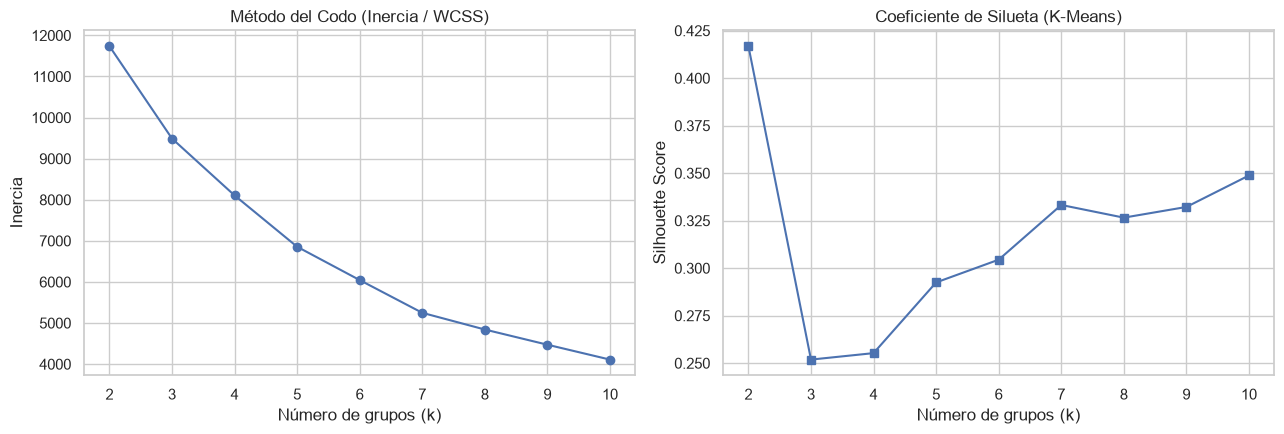

k= 2 | Inercia=  11738.01 | Silueta=0.4168
k= 3 | Inercia=   9489.46 | Silueta=0.2519
k= 4 | Inercia=   8105.86 | Silueta=0.2553
k= 5 | Inercia=   6856.21 | Silueta=0.2925
k= 6 | Inercia=   6045.09 | Silueta=0.3044
k= 7 | Inercia=   5248.63 | Silueta=0.3333
k= 8 | Inercia=   4842.08 | Silueta=0.3266
k= 9 | Inercia=   4472.45 | Silueta=0.3322
k=10 | Inercia=   4110.15 | Silueta=0.3488


In [16]:
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels_k = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(list(k_range), inertias, marker="o")
axes[0].set_title("Método del Codo (Inercia / WCSS)")
axes[0].set_xlabel("Número de grupos (k)")
axes[0].set_ylabel("Inercia")

axes[1].plot(list(k_range), sil_scores, marker="s")
axes[1].set_title("Coeficiente de Silueta (K-Means)")
axes[1].set_xlabel("Número de grupos (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

for k, iner, sil in zip(k_range, inertias, sil_scores):
    print(f"k={k:2d} | Inercia={iner:10.2f} | Silueta={sil:.4f}")

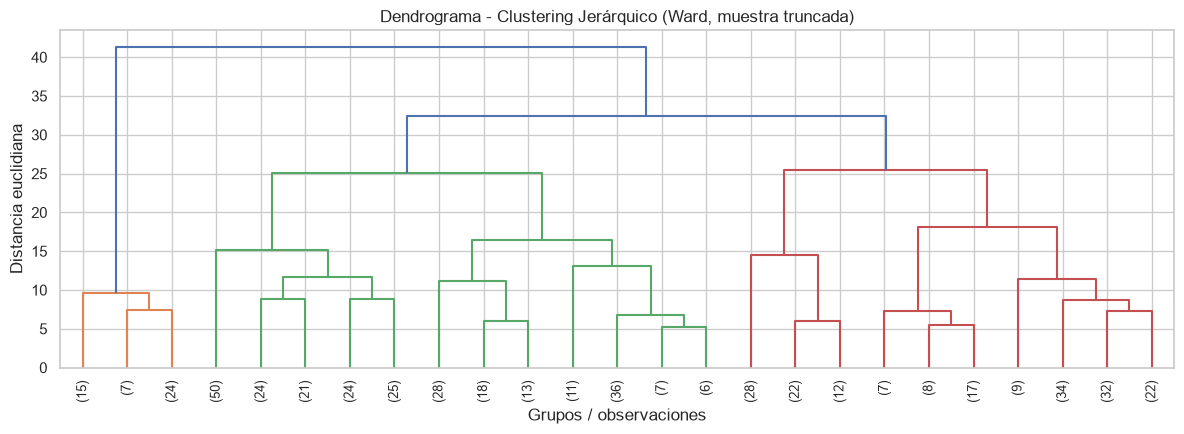

Silueta K-Means (k=4): 0.2553
Silueta Jerárquico Ward (k=4): 0.2592
Concordancia entre K-Means y Jerárquico (ARI): 0.4452


In [17]:
# Elige k según el balance entre codo y mayor silueta (ejemplo: k = 4)
BEST_K = 4

kmeans = KMeans(n_clusters=BEST_K, random_state=42, n_init=20)
df["cluster_kmeans"] = kmeans.fit_predict(X_scaled)

# Dendrograma sobre una muestra si el dataset es grande (ej. 500 filas para legibilidad visual)
sample_size = min(500, len(X_scaled))
rng = np.random.default_rng(42)
idx_sample = rng.choice(len(X_scaled), size=sample_size, replace=False)

Z = linkage(X_scaled[idx_sample], method="ward")
plt.figure(figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=25, leaf_rotation=90, leaf_font_size=9)
plt.title("Dendrograma - Clustering Jerárquico (Ward, muestra truncada)")
plt.xlabel("Grupos / observaciones")
plt.ylabel("Distancia euclidiana")
plt.tight_layout()
plt.show()

agg = AgglomerativeClustering(n_clusters=BEST_K, linkage="ward")
df["cluster_jerarquico"] = agg.fit_predict(X_scaled)

sil_kmeans = silhouette_score(X_scaled, df["cluster_kmeans"])
sil_agg = silhouette_score(X_scaled, df["cluster_jerarquico"])
ari_agreement = adjusted_rand_score(df["cluster_kmeans"], df["cluster_jerarquico"])

print(f"Silueta K-Means (k={BEST_K}): {sil_kmeans:.4f}")
print(f"Silueta Jerárquico Ward (k={BEST_K}): {sil_agg:.4f}")
print(f"Concordancia entre K-Means y Jerárquico (ARI): {ari_agreement:.4f}")

Varianza explicada PC1: 27.59%, PC2: 18.48%, Total 2D: 46.07%

Cargas de variables en PCA:
                PC1    PC2
N           -0.302  0.334
P            0.644  0.034
K            0.623  0.284
temperature -0.212  0.359
humidity    -0.068  0.738
ph          -0.227 -0.221
rainfall    -0.073  0.290


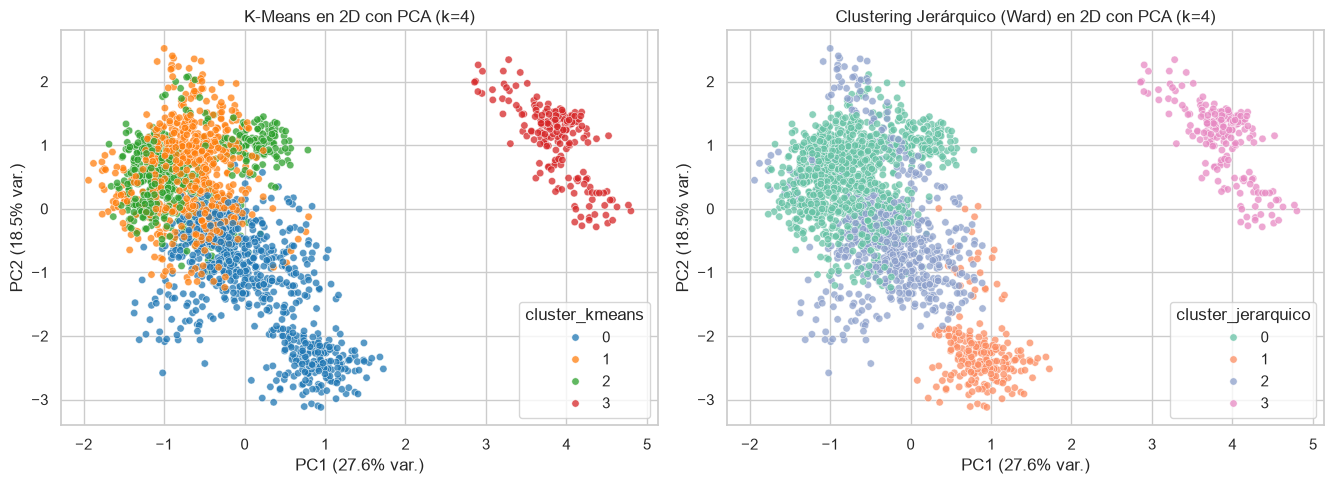

In [18]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df["PC1"] = X_pca[:, 0]
df["PC2"] = X_pca[:, 1]

explained = pca.explained_variance_ratio_
print(f"Varianza explicada PC1: {explained[0]*100:.2f}%, PC2: {explained[1]*100:.2f}%, Total 2D: {explained.sum()*100:.2f}%")

loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=feature_cols
)
print("\nCargas de variables en PCA:\n", loadings.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

sns.scatterplot(
    data=df, x="PC1", y="PC2", hue="cluster_kmeans",
    palette="tab10", alpha=0.75, s=28, ax=axes[0]
)
axes[0].set_title(f"K-Means en 2D con PCA (k={BEST_K})")
axes[0].set_xlabel(f"PC1 ({explained[0]*100:.1f}% var.)")
axes[0].set_ylabel(f"PC2 ({explained[1]*100:.1f}% var.)")

sns.scatterplot(
    data=df, x="PC1", y="PC2", hue="cluster_jerarquico",
    palette="Set2", alpha=0.75, s=28, ax=axes[1]
)
axes[1].set_title(f"Clustering Jerárquico (Ward) en 2D con PCA (k={BEST_K})")
axes[1].set_xlabel(f"PC1 ({explained[0]*100:.1f}% var.)")
axes[1].set_ylabel(f"PC2 ({explained[1]*100:.1f}% var.)")

plt.tight_layout()
plt.show()

In [19]:
perfil_clusters = df.groupby("cluster_kmeans")[feature_cols].agg(["mean", "median"]).round(2)
display(perfil_clusters)

if target_col:
    print("\nDistribución de cultivos (label) más frecuentes por clúster:")
    for c_id, grp in df.groupby("cluster_kmeans"):
        top_crops = grp[target_col].value_counts().head(5).to_dict()
        print(f"  Cluster {c_id} (n={len(grp)}): {top_crops}")

# Guardar artefacto del modelo no supervisado en modelos/
MODELS_DIR = Path("modelos")
MODELS_DIR.mkdir(exist_ok=True)

artefacto_no_supervisado = {
    "scaler": scaler,
    "kmeans": kmeans,
    "pca": pca,
    "n_clusters": BEST_K,
    "feature_cols": feature_cols,
    "metrics": {
        "silhouette_kmeans": float(sil_kmeans),
        "silhouette_hierarchical": float(sil_agg),
        "ari_kmeans_vs_hierarchical": float(ari_agreement),
        "pca_explained_variance_ratio": explained.tolist(),
    },
}

out_path = MODELS_DIR / "modelo_no_supervisado.joblib"
joblib.dump(artefacto_no_supervisado, out_path)
print(f"\nModelo guardado en: {out_path.resolve()}")

N              P              K        temperature         \
                 mean median    mean median    mean median        mean median   
cluster_kmeans                                                                  
0               26.09   26.0   57.52   60.0   28.64   22.0       26.04  27.39   
1               47.73   39.0   32.59   29.0   33.37   36.0       25.14  24.96   
2               96.63  100.0   42.29   40.0   38.42   46.0       26.35  25.99   
3               21.99   24.0  133.38  135.0  200.00  200.0       23.24  22.63   

               humidity           ph        rainfall          
                   mean median  mean median     mean  median  
cluster_kmeans                                                
0                 50.33  53.54  6.54   6.55    79.17   71.58  
1                 85.60  89.93  6.55   6.55   165.35  167.05  
2                 80.04  81.97  6.46   6.42    75.41   75.82  
3                 87.10  87.00  5.98   5.94    91.13   87.52


Distribución de cultivos (label) más frecuentes por clúster:
  Cluster 0 (n=797): {'chickpea': 100, 'kidneybeans': 100, 'mothbeans': 100, 'blackgram': 100, 'lentil': 100}
  Cluster 1 (n=618): {'rice': 100, 'pomegranate': 100, 'orange': 100, 'coconut': 100, 'jute': 99}
  Cluster 2 (n=585): {'banana': 100, 'watermelon': 100, 'muskmelon': 100, 'cotton': 100, 'maize': 82}
  Cluster 3 (n=200): {'grapes': 100, 'apple': 100}

Modelo guardado en: C:\Users\magan\AgroVision\informes\modelos\modelo_no_supervisado.joblib
